In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

In [19]:
df = pd.read_csv('train (4).csv',usecols=['Cabin','Embarked','Age'])

In [20]:
df.head()

,Age,Cabin,Embarked
0,22.0,NaN,S
1,38.0,C85,C
2,26.0,NaN,S
3,35.0,C123,S
4,35.0,NaN,S


In [21]:
df.isnull().mean()*100

Age         19.865320
Cabin       77.104377
Embarked     0.224467
dtype: float64

Text(0, 0.5, 'Number of people')

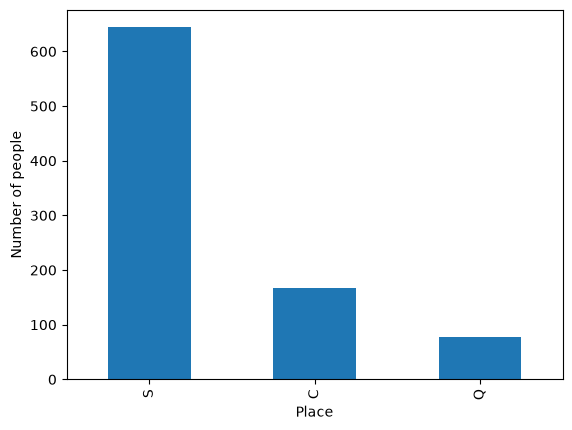

In [22]:
df['Embarked'].value_counts().sort_values(ascending=False).plot.bar()
plt.xlabel('Place')
plt.ylabel('Number of people')

In [31]:
temp = df[df['Embarked']=='S']['Age']

Text(0.5, 1.0, 'Embarked')

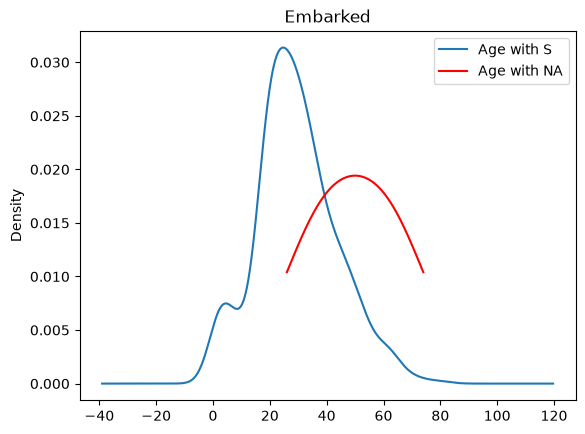

In [32]:
fig = plt.figure()
ax = fig.add_subplot(111)

df[df['Embarked']=='S']['Age'].plot(kind='kde',ax=ax)
df[df['Embarked'].isnull()]['Age'].plot(kind='kde',ax=ax, color='red')

lines,labels = ax.get_legend_handles_labels()
labels = ['Age with S','Age with NA']
ax.legend(lines,labels,loc='best')

plt.title('Embarked')

In [33]:
df['Embarked'].fillna('S',inplace=True)


C:\Users\Aman Chauhan\AppData\Local\Temp\ipykernel_4204\3318131711.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['Embarked'].fillna('S',inplace=True)


0      S
1      C
2      S
3      S
4      S
      ..
886    S
887    S
888    S
889    C
890    Q
Name: Embarked, Length: 891, dtype: str

<Axes: xlabel='Embarked'>

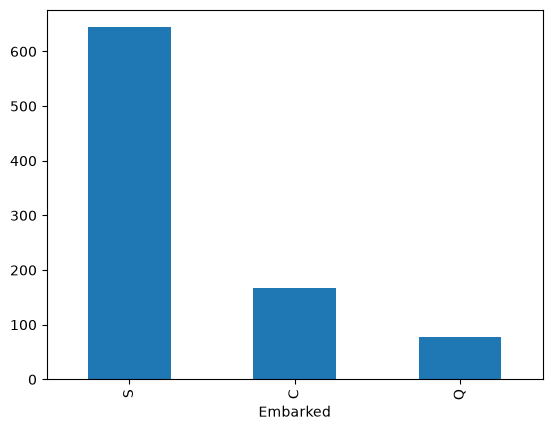

In [34]:
df['Embarked'].value_counts().plot(kind='bar')

Text(0.5, 1.0, 'Embarked')

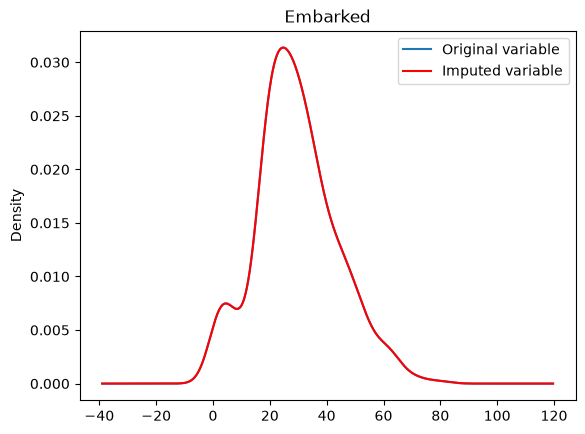

In [35]:
fig = plt.figure()
ax = fig.add_subplot(111)

temp.plot(kind='kde',ax=ax)

df[df['Embarked'] == 'S']['Age'].plot(kind='kde',ax=ax, color='red')

lines,labels = ax.get_legend_handles_labels()
labels = ['Original variable','Imputed variable']
ax.legend(lines,labels,loc='best')

plt.title('Embarked')

In [36]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(df.drop(columns=['Age']),df['Age'],test_size=0.2)

In [37]:
from sklearn.impute import SimpleImputer

In [38]:
imputer = SimpleImputer(strategy='most_frequent')

In [41]:
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_train)

In [42]:
imputer.statistics_

array(['G6', 'S'], dtype=object)